## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as ss
import pingouin as pg
from statsmodels.stats.multicomp import pairwise_tukeyhsd

---

## Data Overview

### Data Import and Structure

The CSV file uses semicolons to separate columns and commas as decimal marks, so `sep=";"` and `decimal=","` were used to import the data correctly.

In [2]:
df = pd.read_csv("../data/Scores.csv", sep=";", index_col=0, decimal=",")
df.head()

,student_id,gender,parental.level.of.education,subject,score
1,id_001,female,high school,math,23.0
2,id_001,female,high school,language,40.0
3,id_002,female,high school,math,68.0
4,id_002,female,high school,language,80.5
5,id_003,male,high school,math,82.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 972 entries, 1 to 972
Data columns (total 5 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   student_id                   972 non-null    str    
 1   gender                       972 non-null    str    
 2   parental.level.of.education  972 non-null    str    
 3   subject                      972 non-null    str    
 4   score                        972 non-null    float64
dtypes: float64(1), str(4)
memory usage: 38.1 KB


In [4]:
df.nunique()

student_id                     486
gender                           2
parental.level.of.education      4
subject                          2
score                          133
dtype: int64

In [5]:
df.isna().sum()

student_id                     0
gender                         0
parental.level.of.education    0
subject                        0
score                          0
dtype: int64

The dataset contains 972 rows and 5 columns. It includes 486 unique students, 2 gender categories, 4 parental education levels, and 2 subject categories. The data are stored in long format, where each student has one Mathematics score and one Language score. No missing values were found in the dataset.

---

### Group Sizes and Data Integrity

In [6]:
records_per_student = df.groupby("student_id")["score"].agg("count")
records_per_student.agg(["min", "max"])

min    2
max    2
Name: score, dtype: int64

Each student has exactly two score records, which confirms that both subject scores are available for every student.

In [7]:
gender_counts = df.groupby("gender")["student_id"].nunique()
gender_counts

gender
female    245
male      241
Name: student_id, dtype: int64

The gender groups are almost balanced, with 245 female students and 241 male students.

In [8]:
education_counts = df.groupby("parental.level.of.education")["student_id"].nunique()
education_counts

parental.level.of.education
associate's degree    177
bachelor's degree      94
high school           156
master's degree        59
Name: student_id, dtype: int64

The parental education groups are unbalanced, with the largest group being associate’s degree and the smallest group being master’s degree.

In [9]:
subject_counts = df.groupby("subject")["student_id"].nunique()
subject_counts

subject
language    486
math        486
Name: student_id, dtype: int64

Both subjects have 486 student records, so Mathematics and Language scores are available for all students.

---

## Descriptive Statistics

In [10]:
df.groupby("subject")["score"].agg(["count", "mean", "median", "std", "min", "max"]).round(1)

,count,mean,median,std,min,max
subject,,,,,,
language,486,69.0,70.0,14.4,19.5,100.0
math,486,66.4,66.0,15.1,23.0,100.0


This table shows that language scores are slightly higher than mathematics scores on average.

In [11]:
df.groupby(["subject", "gender"])["score"].agg(["count", "mean", "median", "std", "min", "max"]).round(1)

count  mean  median   std   min    max
subject  gender                                        
language female    245  73.0    73.0  14.0  29.5  100.0
         male      241  64.9    65.5  13.8  19.5  100.0
math     female    245  63.9    64.0  15.3  23.0  100.0
         male      241  68.9    70.0  14.4  30.0  100.0

This table suggests that female students have higher language scores on average, while male students have higher mathematics scores on average.

In [12]:
df.groupby(["subject","parental.level.of.education"])["score"].agg(["count", "mean", "median", "std", "min", "max"]).round(1)

count  mean  median   std   min    max
subject  parental.level.of.education                                        
language associate's degree             177  70.0    72.0  14.2  34.5  100.0
         bachelor's degree               94  72.1    73.0  14.3  40.0  100.0
         high school                    156  63.5    65.0  13.4  19.5   99.5
         master's degree                 59  75.5    76.0  13.6  44.0  100.0
math     associate's degree             177  67.8    66.0  15.2  26.0  100.0
         bachelor's degree               94  68.4    67.0  15.0  29.0  100.0
         high school                    156  62.2    63.0  14.0  23.0   94.0
         master's degree                 59  69.7    73.0  15.2  40.0   95.0

Students with higher parental education levels generally have higher average scores in both mathematics and language.

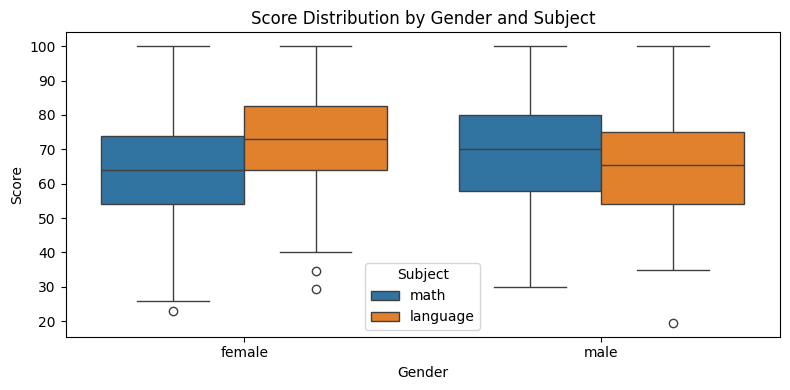

In [13]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="gender", y="score", hue="subject")
plt.xlabel("Gender")
plt.ylabel("Score")
plt.title("Score Distribution by Gender and Subject")
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

The boxplot shows that female students tend to have higher language scores, while male students tend to have higher mathematics scores.

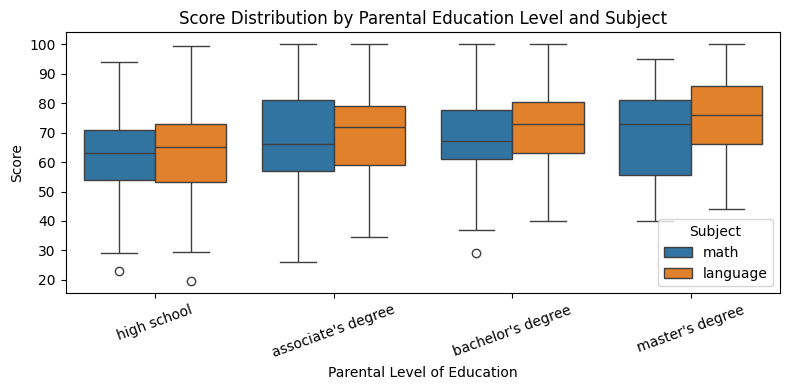

In [14]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="parental.level.of.education", y="score", hue="subject")
plt.xlabel("Parental Level of Education")
plt.ylabel("Score")
plt.title("Score Distribution by Parental Education Level and Subject")
plt.xticks(rotation=20)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

Students with higher parental education levels tend to have higher scores in both subjects, especially in language.

---

## Hypothesis Testing

### Mathematics Scores and Gender

**Research question:** "Is there a statistically significant difference between male and female students in their Mathematics scores?"

In this research question, we investigate whether there is a significant difference in mathematics scores between male and female students. Gender is a categorical variable with two independent groups: male and female. Mathematics score is a numerical variable, so comparing group means is more appropriate than comparing proportions. Proportions are generally used for categorical outcomes such as yes/no or true/false variables.   

In addition, the dataset represents a sample rather than the entire populations. In real world, researchers usually work with sample data because population data are rarely available. Therefore, the population variance is typically unknown. For this reason, a z-test is not appropriate, while a t-test can be used. Since both group sizes are above 30 (male=241, female=245), the Central Limit Theorem suggests that the sampling distribution is approximately normal.   

There are two common types of independent t-tests: the pooled t-test and Welch's t-test. The pooled t-test assumes equal variances between two groups. However, population variances are unknown, so this assumption cannot be justified in this study.   

Therefore, Welch's t-test was selected. Welch's t-test does not require the assumption of equal variances and is generally considered a more robust method when population variances are uncertain.

$H_0:$ $\mu_{male} = \mu_{female}$ (The mean Mathematics score of male students is *equal* to the mean Mathematics score of female students.)   
$H_1:$ $\mu_{male} \neq \mu_{female}$ (The mean Mathematics score of male students is **not** *equal* to the mean Mathematics score of female students.)


In [15]:
male_math_scores = df[(df["gender"] == "male") & (df["subject"] == "math")]["score"]
female_math_scores = df[(df["gender"] == "female") & (df["subject"] == "math")]["score"]
print(f"male: {male_math_scores.mean().round(2)}")
print(f"female: {female_math_scores.mean().round(2)}")

male: 68.95
female: 63.86


In [16]:
t_stat, p_value = ss.ttest_ind(male_math_scores, female_math_scores, equal_var=False)
print(f"t = {t_stat:.4f}, p = {p_value:.4f}")

t = 3.7782, p = 0.0002


The Welch's t-test produces two key outputs: the test statistic and the p-value. The test statistic is t = 3.78, and the p-value is p = 0.0002.   
Since the p-value is well below the significance level of α = 0.05, the null hypothesis is rejected.   
This indicates that there is a statistically significant difference between male and female students in Mathematics scores.

In [17]:
print(f"d = {pg.compute_effsize(male_math_scores, female_math_scores, eftype="cohen").round(2)}")

d = 0.34


Although the Welch's t-test indicates a statistically significant difference, statistical significance alone does not tell us whether the difference is meaningful in practice.   
To assess the practical importance of the result, Cohen's d was calculated as a measure of effect size.   

The result is d = 0.34. According to Cohen (1988), the commonly used thresholds are 0.2 for a small effect, 0.5 for a medium effect, and 0.8 for a large effect.   
Since d = 0.34 falls between these first two thresholds, the effect size is considered small to medium.

---

### Language Scores and Gender

**Research question:** “Is there a statistically significant difference between male and female students in their Language scores?

The same methodology was applied to Language scores. The hypothesis test selection process is the same as in the previous section.

$H_0: \mu_{male} = \mu_{female}$ (The mean Language score of male students *equal to* the mean Language score of female students.)   
$H_1: \mu_{male} \neq \mu_{female}$ (The mean Language score of male students **not** *equal to* the mean Language score of female students.)  

In [18]:
male_language_scores = df[(df["gender"] == "male") & (df["subject"] == "language")]["score"]
female_language_scores = df[(df["gender"] == "female") & (df["subject"] == "language")]["score"]
print(f"male: {male_language_scores.mean().round(2)}")
print(f"female: {female_language_scores.mean().round(2)}")

male: 64.93
female: 73.0


In [19]:
t_stat, p_value = ss.ttest_ind(female_language_scores, male_language_scores, equal_var=False)
print(f"t = {t_stat:.4f}, p = {p_value:.2e}")

t = 6.4096, p = 3.47e-10


The test statistics is 6.4096 and p-value is 3.47e-10 (<0.001).   
Since p-value is lower than the significance level of $\alpha = 0.05$, the null hypothesis is rejected.   
There is a statistically significant difference between male and female students in Language scores.

In [20]:
print(f"d = {pg.compute_effsize(female_language_scores, male_language_scores, eftype="cohen").round(2)}")

d = 0.58


Additionally, Cohen's d was calculated to measure the practical significance of the result.   
The effect size is d = 0.58, which indicates a medium effect according to Cohen (1988).

---

### Parental Education Levels and Scores

**Research question:** "Is there a difference in scores across parental education levels?"

This section investigates whether there is a statistically significant difference in scores across parental education levels. In the research question, there are more than two independent groups: high school, associate's degree, bachelor's degree, and master's degree. Therefore, a one-way ANOVA (F-test) was selected. This test is the standard choice when comparing means across three or more independent groups.

The research question does not specify which score group is meant.   
Since the dataset contains two separate score groups — Mathematics and Language — a one-way ANOVA test was applied to each group independently.

$H_0:$ Mean Mathematics scores of all groups are equal. ($\mu1=\mu2=\mu3=\mu4$)   
$H_1:$ At least one group mean is different from the others.

In [21]:
high_school_math_scores = df[(df["parental.level.of.education"] == "high school") & (df["subject"] == "math")]["score"]
associates_degree_math_scores = df[(df["parental.level.of.education"] == "associate's degree") & (df["subject"] == "math")]["score"]
bachelors_degree_math_scores = df[(df["parental.level.of.education"] == "bachelor's degree") & (df["subject"] == "math")]["score"]
masters_degree_math_scores = df[(df["parental.level.of.education"] == "master's degree") & (df["subject"] == "math")]["score"]

In [22]:
F_statistic, p_value = ss.f_oneway(high_school_math_scores, associates_degree_math_scores, bachelors_degree_math_scores, masters_degree_math_scores)
print(f"F = {F_statistic.round(2)}, p = {p_value:.4f}")

F = 6.22, p = 0.0004


The test statistics is 6.22 and p-value is 0.0004.   
Since p-value well below than significance level of $\alpha = 0.05$, therefore the null hypothesis is rejected.   
There is a statistically significant difference between parental education levels and math scores.

The F-test provides a general result and does not indicate which specific groups differ.   
Therefore, the Tukey HSD test was applied, as it performs pairwise comparisons between all groups and identifies which specific pairs differ significantly.

In [23]:
math_scores = df[df["subject"] == "math"]["score"]
parental_level_of_education = df[df["subject"] == "math"]["parental.level.of.education"]

tukeyhsd = pairwise_tukeyhsd(endog=math_scores, groups=parental_level_of_education, alpha=0.05)
print(tukeyhsd)

            Multiple Comparison of Means - Tukey HSD, FWER=0.05             
      group1             group2      meandiff p-adj   lower    upper  reject
----------------------------------------------------------------------------
associate's degree bachelor's degree   0.6226 0.9877  -4.2525  5.4977  False
associate's degree       high school    -5.57 0.0037  -9.7649 -1.3751   True
associate's degree   master's degree   1.9322 0.8217  -3.8102  7.6746  False
 bachelor's degree       high school  -6.1926 0.0079 -11.1802  -1.205   True
 bachelor's degree   master's degree   1.3096 0.9512   -5.035  7.6542  False
       high school   master's degree   7.5022 0.0055   1.6639 13.3404   True
----------------------------------------------------------------------------


The Tukey HSD results reveal three statistically significant pairwise differences, all involving the high school group.   
The high school group differs significantly from the associate's degree (p = 0.0037), the bachelor's degree (p = 0.0079), and the master's degree (p = 0.0055).   
No significant difference was found among the associate's degree, bachelor's degree, and master's degree groups.


In [24]:
data = df[df["subject"] == "math"]
eta_squared = pg.anova(data=data, dv="score", between="parental.level.of.education", effsize="n2")
print(eta_squared)

                        Source  ddof1  ddof2         F     p_unc        n2
0  parental.level.of.education      3    482  6.222926  0.000375  0.037288


The effect size was measured using eta squared ($\eta^2$). The result is $\eta^2$ = 0.037, which indicates a small to medium effect according to Cohen (1988).

---

The same methodology was applied to Language scores.

$H_0:$ Mean Language scores of all groups are equal. ($\mu1=\mu2=\mu3=\mu4$)   
$H_1:$ At least one group mean is different from the others.

In [25]:
high_school_language_scores = df[(df["parental.level.of.education"] == "high school") & (df["subject"] == "language")]["score"]
associates_degree_language_scores = df[(df["parental.level.of.education"] == "associate's degree") & (df["subject"] == "language")]["score"]
bachelors_degree_language_scores = df[(df["parental.level.of.education"] == "bachelor's degree") & (df["subject"] == "language")]["score"]
masters_degree_language_scores = df[(df["parental.level.of.education"] == "master's degree") & (df["subject"] == "language")]["score"]

In [26]:
F_statistic, p_value = ss.f_oneway(high_school_language_scores, associates_degree_language_scores, bachelors_degree_language_scores, masters_degree_language_scores)
print(f"F = {F_statistic.round(2)}, p = {p_value:.2e}")

F = 14.24, p = 6.62e-09


The test statistic is 14.24 and p-value is 6.62e-09 (<0.001).   
Since p-value is well below than significance level $\alpha = 0.05$, therefore the null hypothesis is rejected.   
There is a statistically significant difference between parental education levels and language scores.

In [27]:
language_scores = df[df["subject"] == "language"]["score"]
parental_level_of_education = df[df["subject"] == "language"]["parental.level.of.education"]

tukeyhsd_2 = pairwise_tukeyhsd(endog=language_scores, groups=parental_level_of_education, alpha=0.05)
print(tukeyhsd_2)

            Multiple Comparison of Means - Tukey HSD, FWER=0.05             
      group1             group2      meandiff p-adj   lower    upper  reject
----------------------------------------------------------------------------
associate's degree bachelor's degree   2.0359 0.6596  -2.5337  6.6055  False
associate's degree       high school  -6.4905 0.0001 -10.4226 -2.5585   True
associate's degree   master's degree   5.5028 0.0429   0.1202 10.8854   True
 bachelor's degree       high school  -8.5265    0.0 -13.2016 -3.8514   True
 bachelor's degree   master's degree   3.4669 0.4365  -2.4802   9.414  False
       high school   master's degree  11.9934    0.0    6.521 17.4658   True
----------------------------------------------------------------------------


The Tukey HSD results reveal four statistically significant pairwise differences.   
The associate's degree group differs significantly from master's degree group (p=0.0429). The remaining three significant differences all involve the high school group.   
The high school group differs significantly from the associate's degree (p = 0.0001), the bachelor's degree (p < 0.0001), and the master's degree (p < 0.0001) groups.   
No significant difference was found among the other pairwise groups.

In [28]:
data = df[df["subject"] == "language"]
eta_squared_2 = pg.anova(data=data, dv="score", between="parental.level.of.education", effsize="n2")
print(eta_squared_2)

                        Source  ddof1  ddof2         F         p_unc        n2
0  parental.level.of.education      3    482  14.24059  6.617864e-09  0.081418


The effect size was measured using eta squared ($\eta^2$). The result is $\eta^2$ = 0.081, which indicates a medium to large effect according to Cohen (1988).